# 5 gráficos con Matplotlib y Seaborn — Ventas de Superstore

**Autora:** Lorena Herranz Pascual

**Enunciado:** elegir 5 gráficos (*charts*) y hacer un cuaderno que muestre esos 5 gráficos con **Matplotlib** y esos mismos, en el mismo cuaderno, con **Seaborn**. Después, mostrar los 5 gráficos en una página con **Streamlit** (`app.py`).

**De dónde salen los gráficos:** he elegido 5 tipos del cuaderno de clase `matplotlib.ipynb` (*Chart Chooser*), uno de cada familia, y he usado su misma configuración (paleta `PAL`, `rcParams` y la función `ygrid`). He cambiado sus datos de ejemplo por datos reales de Kaggle.

| # | Gráfico (cuaderno de clase) | Familia | Pregunta |
|---|---|---|---|
| 1 | Single Bar Chart | Comparación (estática) | ¿Qué subcategoría vende más? |
| 2 | Line Chart, muchos periodos | Comparación (cambio en el tiempo) | ¿Cómo evolucionan las ventas mes a mes? |
| 3 | Scatter Chart | Relación | ¿Los clientes que más compran son los que más beneficio dejan? |
| 4 | Column Histogram | Distribución | ¿Cuántos días se tarda en enviar un pedido? |
| 5 | Stacked Column Chart | Composición (pocos periodos) | ¿Cuánto se vende cada año y cómo se reparte por categoría? |

**Datos:** [Superstore Dataset (Kaggle)](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final). Son las ventas de una tienda de Estados Unidos: cada fila es una línea de un pedido, con fecha, cliente, región, categoría, ventas ($), cantidad, descuento y beneficio ($).

## Matplotlib frente a Seaborn

- **Matplotlib** es la librería base: dibuja exactamente lo que le dices. Antes hay que preparar los datos (agrupar, sumar, contar) y, si hay varias categorías, recorrerlas en un bucle.
- **Seaborn** funciona *encima* de matplotlib. Le pasas el DataFrame y los nombres de columna (`x=`, `y=`, `hue=`) y él agrupa, suma, colorea y pone la leyenda. Lo que dibuja sigue siendo un gráfico de matplotlib, así que se retoca igual (`ax.set_title`, `ax.set_xlabel`…).

## 0. Preparación

In [1]:
# Si seaborn no está instalado (en Colab ya viene), descomenta la línea siguiente:
# !pip install seaborn

import numpy as np                  # numpy: cálculos con arrays (posiciones de las barras apiladas)
import pandas as pd                 # pandas: leer el CSV y trabajar con la tabla (DataFrame)
import matplotlib.pyplot as plt     # matplotlib: la librería base que dibuja
import matplotlib.ticker as mtick   # ticker: dar formato a los números de los ejes (miles, $)
import seaborn as sns               # seaborn: gráficos estadísticos a partir del DataFrame
from pathlib import Path            # Path: comprobar si el CSV existe en local

# ---- Configuración copiada del cuaderno de clase (matplotlib.ipynb) ----
SURFACE = "#fcfcfb"                                   # color de fondo
TEXT, TEXT2, GRID = "#0b0b0b", "#52514e", "#e3e2de"   # texto principal, texto secundario y rejilla
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # paleta de colores

plt.rcParams.update({   # rcParams = ajustes por defecto de matplotlib; seaborn también los respeta
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "text.color": TEXT, "axes.titlelocation": "left", "axes.titleweight": "semibold",
    "axes.titlesize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False,
    "font.size": 10, "figure.dpi": 110,
})

def xgrid(ax):          # rejilla solo vertical (función del cuaderno de clase)
    ax.grid(False)
    ax.grid(True, axis="x")

def ygrid(ax):          # rejilla solo horizontal (función del cuaderno de clase)
    ax.grid(False)
    ax.grid(True, axis="y")

MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
miles = mtick.FuncFormatter(lambda v, pos: f"{v/1000:,.0f}k".replace(",", "."))  # 150000 → "150k" en los ejes

### Cargar los datos

El CSV de Kaggle está guardado en `datos/superstore.csv` (le he cambiado el nombre a `Sample - Superstore.csv` para quitar los espacios). Lleva acentos y símbolos de Windows, así que se lee con `encoding="latin-1"`.

In [2]:
RUTA_LOCAL = Path("datos/superstore.csv")   # ruta dentro del proyecto
URL_GITHUB = "https://raw.githubusercontent.com/HerranzP-Lorena/graficos-superstore/main/datos/superstore.csv"
origen = RUTA_LOCAL if RUTA_LOCAL.exists() else URL_GITHUB   # si no está en local (p. ej. en Colab), lo baja de GitHub

df = pd.read_csv(origen, encoding="latin-1")   # latin-1: el archivo no está en UTF-8 y daría error de caracteres
print(df.shape)                                # (filas, columnas)
df.head()                                      # 5 primeras filas

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
df.info()   # nombre y tipo de cada columna, y cuántos valores no nulos tiene

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

### Limpiar y preparar

- Convertir las fechas de texto a fecha real.
- Quitar filas incompletas, si las hay.
- Crear las columnas que necesitan los gráficos: año, días de envío y nombres en español.

In [4]:
# 1) Fechas: en el CSV vienen como texto "11/8/2017" (mes/día/año, formato de EE. UU.)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")   # fecha del pedido
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")     # fecha de envío

# 2) Quitar filas a las que les falte algún dato de los que vamos a usar
columnas = ["Order Date", "Ship Date", "Category", "Sub-Category", "Customer ID", "Sales", "Profit"]
antes = len(df)
df = df.dropna(subset=columnas)      # dropna borra las filas con algún vacío en esas columnas
print(f"Filas eliminadas por datos vacíos: {antes - len(df)}")

# 3) Columnas nuevas
df["Año"] = df["Order Date"].dt.year.astype(str)                 # año del pedido, como texto para usarlo como categoría
df["Días de envío"] = (df["Ship Date"] - df["Order Date"]).dt.days   # restar fechas da días entre pedido y envío

# 4) Traducir categorías y subcategorías al español (diccionario: inglés → español)
CATEGORIAS = {"Furniture": "Muebles", "Office Supplies": "Material de oficina", "Technology": "Tecnología"}
SUBCATEGORIAS = {
    "Phones": "Teléfonos", "Chairs": "Sillas", "Storage": "Almacenaje", "Tables": "Mesas",
    "Binders": "Archivadores", "Machines": "Máquinas", "Accessories": "Accesorios", "Copiers": "Copiadoras",
    "Bookcases": "Estanterías", "Appliances": "Electrodomésticos", "Furnishings": "Decoración",
    "Paper": "Papel", "Supplies": "Suministros", "Art": "Material de dibujo", "Envelopes": "Sobres",
    "Labels": "Etiquetas", "Fasteners": "Grapas y clips",
}
df["Categoría"] = df["Category"].map(CATEGORIAS)          # map sustituye cada valor por su traducción
df["Subcategoría"] = df["Sub-Category"].map(SUBCATEGORIAS)

ORDEN_CAT = ["Tecnología", "Muebles", "Material de oficina"]   # orden fijo de las categorías
COLOR_CAT = dict(zip(ORDEN_CAT, PAL))                          # {categoría: color}, siempre el mismo

df[["Order Date", "Año", "Días de envío", "Categoría", "Subcategoría", "Sales", "Profit"]].head()

Filas eliminadas por datos vacíos: 0


,Order Date,Año,Días de envío,Categoría,Subcategoría,Sales,Profit
0,2016-11-08,2016,3,Muebles,Estanterías,261.9600,41.9136
1,2016-11-08,2016,3,Muebles,Sillas,731.9400,219.5820
2,2016-06-12,2016,4,Material de oficina,Etiquetas,14.6200,6.8714
3,2015-10-11,2015,7,Muebles,Mesas,957.5775,-383.0310
4,2015-10-11,2015,7,Material de oficina,Almacenaje,22.3680,2.5164


In [5]:
df[["Sales", "Quantity", "Discount", "Profit", "Días de envío"]].describe().round(1)   # resumen estadístico

,Sales,Quantity,Discount,Profit,Días de envío
count,9994.0,9994.0,9994.0,9994.0,9994.0
mean,229.9,3.8,0.2,28.7,4.0
std,623.2,2.2,0.2,234.3,1.7
min,0.4,1.0,0.0,-6600.0,0.0
25%,17.3,2.0,0.0,1.7,3.0
50%,54.5,3.0,0.2,8.7,4.0
75%,209.9,5.0,0.2,29.4,5.0
max,22638.5,14.0,0.8,8400.0,7.0


## 1. Single Bar Chart — Comparación estática

**Pregunta:** ¿qué subcategoría de producto vende más?

*Del cuaderno de clase:* compara el valor de una sola variable entre varias categorías.

- **Cuándo usarlo:** para comparar magnitudes entre categorías. Aquí, ventas por subcategoría.
- **Cómo leerlo:** la longitud de cada barra es el valor; están ordenadas de mayor a menor para ver el ranking.
- **Evitar:** que el eje no empiece en cero, porque exagera las diferencias.

In [6]:
# Datos para las dos versiones: suma de ventas por subcategoría, de mayor a menor
ventas_sub = (
    df.groupby("Subcategoría", as_index=False)["Sales"].sum()   # agrupa y suma las ventas
      .sort_values("Sales", ascending=False)                    # ordena de mayor a menor
)
ventas_sub.head()

,Subcategoría,Sales
16,Teléfonos,330007.054
13,Sillas,328449.103
1,Almacenaje,223843.608
10,Mesas,206965.532
2,Archivadores,203412.733


### 1a. Matplotlib

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


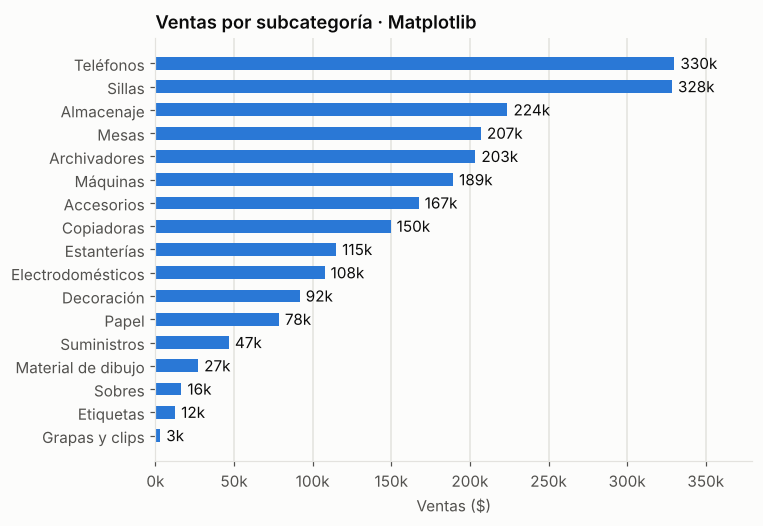

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))                     # figura y ejes (ancho, alto en pulgadas)
bars = ax.barh(ventas_sub["Subcategoría"], ventas_sub["Sales"],   # barh = barras horizontales
               color=PAL[0], height=0.55)                    # un color: es una sola variable
ax.invert_yaxis()                                          # el primero arriba (como en el cuaderno de clase)
ax.bar_label(bars, labels=[f"{v/1000:.0f}k" for v in ventas_sub["Sales"]],   # etiqueta al final de cada barra
             padding=4, color=TEXT)
ax.set_xlim(0, ventas_sub["Sales"].max() * 1.15)           # margen a la derecha para las etiquetas
ax.xaxis.set_major_formatter(miles)                        # eje x en miles: 100k, 200k...
xgrid(ax)                                                  # solo rejilla vertical
ax.set_xlabel("Ventas ($)")
ax.set_title("Ventas por subcategoría · Matplotlib")
plt.show()

### 1b. Seaborn

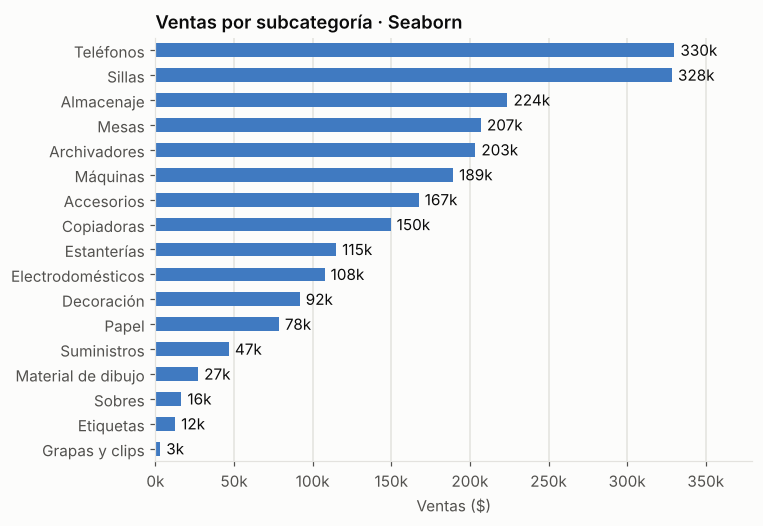

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(
    data=df,                  # ¡el DataFrame SIN agrupar!
    x="Sales", y="Subcategoría",
    estimator="sum",          # seaborn suma las ventas de cada subcategoría por nosotras (hace el groupby)
    errorbar=None,            # sin barras de error (por defecto seaborn pone un intervalo de confianza)
    order=ventas_sub["Subcategoría"],   # mismo orden de mayor a menor
    color=PAL[0], width=0.55, ax=ax,
)
ax.bar_label(ax.containers[0], labels=[f"{v/1000:.0f}k" for v in ventas_sub["Sales"]], padding=4, color=TEXT)
ax.set_xlim(0, ventas_sub["Sales"].max() * 1.15)
ax.xaxis.set_major_formatter(miles)
xgrid(ax)
ax.set(xlabel="Ventas ($)", ylabel="", title="Ventas por subcategoría · Seaborn")
plt.show()

**Diferencia:** matplotlib necesita la tabla ya agrupada (`groupby` + `sum`). Seaborn recibe el DataFrame original y con `estimator="sum"` agrupa él solo.

**Qué se ve:** **Teléfonos** y **sillas** son lo que más vende, unos 330.000 $ cada una. Las subcategorías de material pequeño (sobres, etiquetas, grapas y clips) apenas venden.

## 2. Line Chart (muchos periodos) — Cambio en el tiempo

**Pregunta:** ¿cómo evolucionan las ventas mes a mes?

*Del cuaderno de clase:* una serie de valores a lo largo de muchos periodos (aquí, 48 meses).

- **Cuándo usarlo:** para ver tendencias y cambios de dirección en el tiempo.
- **Cómo leerlo:** la pendiente indica la velocidad del cambio; los picos y valles marcan los momentos clave. Se etiqueta el último valor.
- **Evitar:** cortar el eje vertical lejos de cero si la intención es comparar magnitudes.

In [9]:
# Datos: ventas totales de cada mes
ventas_mes = (
    df.set_index("Order Date")["Sales"]   # usamos la fecha como índice
      .resample("MS").sum()               # resample("MS") = agrupar por mes (MS = Month Start) y sumar
      .reset_index()                      # volver a tabla normal con columnas "Order Date" y "Sales"
)
ventas_mes.tail()

,Order Date,Sales
43,2017-08-01,63120.8880
44,2017-09-01,87866.6520
45,2017-10-01,77776.9232
46,2017-11-01,118447.8250
47,2017-12-01,83829.3188


### 2a. Matplotlib

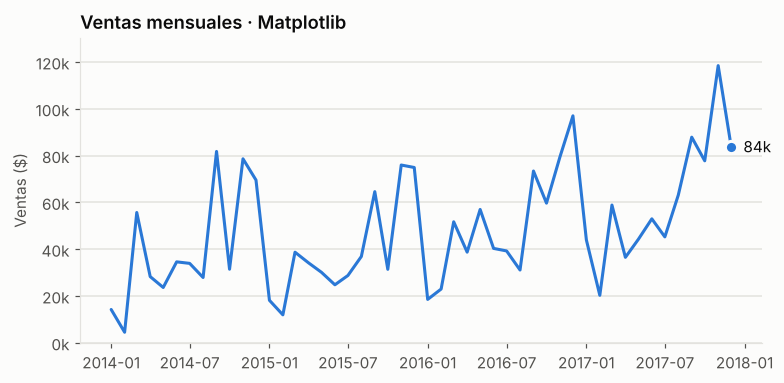

In [10]:
x = ventas_mes["Order Date"]            # fechas (eje x)
y = ventas_mes["Sales"]                 # ventas (eje y)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x, y, color=PAL[0])             # la línea
ax.plot(x.iloc[-1], y.iloc[-1], "o", color=PAL[0], markersize=8,   # punto en el último mes (como en clase)
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"{y.iloc[-1]/1000:.0f}k", (x.iloc[-1], y.iloc[-1]),   # etiqueta con el último valor
            xytext=(8, 0), textcoords="offset points", va="center", color=TEXT)
ax.set_ylim(0, y.max() * 1.1)           # eje desde 0
ax.yaxis.set_major_formatter(miles)
ygrid(ax)
ax.set_ylabel("Ventas ($)")
ax.set_title("Ventas mensuales · Matplotlib")
plt.show()

### 2b. Seaborn

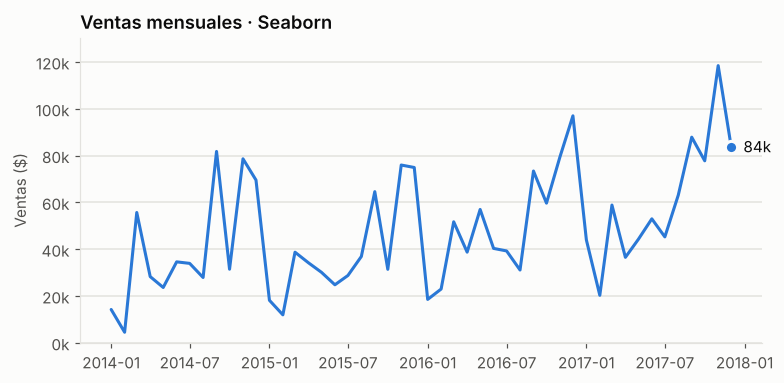

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.lineplot(data=ventas_mes, x="Order Date", y="Sales", color=PAL[0], ax=ax)   # una línea con los datos del DataFrame
ult = ventas_mes.iloc[-1]               # última fila (último mes)
ax.plot(ult["Order Date"], ult["Sales"], "o", color=PAL[0], markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"{ult['Sales']/1000:.0f}k", (ult["Order Date"], ult["Sales"]),
            xytext=(8, 0), textcoords="offset points", va="center", color=TEXT)
ax.set_ylim(0, ventas_mes["Sales"].max() * 1.1)
ax.yaxis.set_major_formatter(miles)
ygrid(ax)
ax.set(xlabel="", ylabel="Ventas ($)", title="Ventas mensuales · Seaborn")
plt.show()

**Diferencia:** con una sola línea casi no hay. `sns.lineplot` lee las columnas por su nombre, y si se le añadiera `hue=` dibujaría una línea por categoría sin necesidad de un bucle.

**Qué se ve:** Las ventas **suben de un año a otro** y se repite el mismo patrón: **picos en septiembre, noviembre y diciembre** y caídas fuertes en **enero y febrero**. La línea sube y baja mucho de un mes a otro, así que la tendencia se aprecia mejor mirando años completos.

## 3. Scatter Chart — Relación

**Pregunta:** ¿los clientes que más compran son los que más beneficio dejan?

*Del cuaderno de clase:* dos variables numéricas; cada punto es un caso. Aquí cada punto es **un cliente**, con sus ventas totales y su beneficio total.

- **Cuándo usarlo:** para ver si dos variables están relacionadas y detectar valores atípicos.
- **Cómo leerlo:** si la nube sube hacia la derecha, hay relación positiva. Los puntos por debajo de la línea del 0 son clientes con los que la tienda **pierde** dinero.
- **Evitar:** interpretar causalidad solo por la correlación.

In [12]:
# Datos: un punto por cliente → sumar ventas y beneficio de cada cliente
clientes = df.groupby("Customer ID", as_index=False)[["Sales", "Profit"]].sum()
print(f"Clientes: {len(clientes)}")
print(f"Correlación ventas–beneficio: {clientes['Sales'].corr(clientes['Profit']):.2f}")  # de -1 a 1
clientes.head()

Clientes: 793
Correlación ventas–beneficio: 0.51


,Customer ID,Sales,Profit
0,AA-10315,5563.560,-362.8825
1,AA-10375,1056.390,277.3824
2,AA-10480,1790.512,435.8274
3,AA-10645,5086.935,857.8033
4,AB-10015,886.156,129.3465


### 3a. Matplotlib

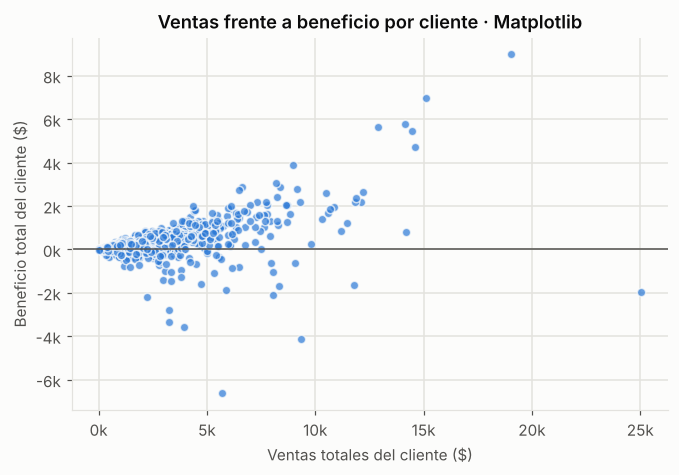

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.scatter(clientes["Sales"], clientes["Profit"], s=30, color=PAL[0], alpha=0.7,   # alpha: transparencia, hay muchos puntos
           edgecolor=SURFACE, linewidth=1)    # anillo de superficie (como en clase)
ax.axhline(0, color=TEXT2, linewidth=1)       # línea horizontal en beneficio 0: debajo = pérdidas
ax.xaxis.set_major_formatter(miles)
ax.yaxis.set_major_formatter(miles)
ax.set_xlabel("Ventas totales del cliente ($)")
ax.set_ylabel("Beneficio total del cliente ($)")
ax.set_title("Ventas frente a beneficio por cliente · Matplotlib", loc="center")
plt.show()

### 3b. Seaborn

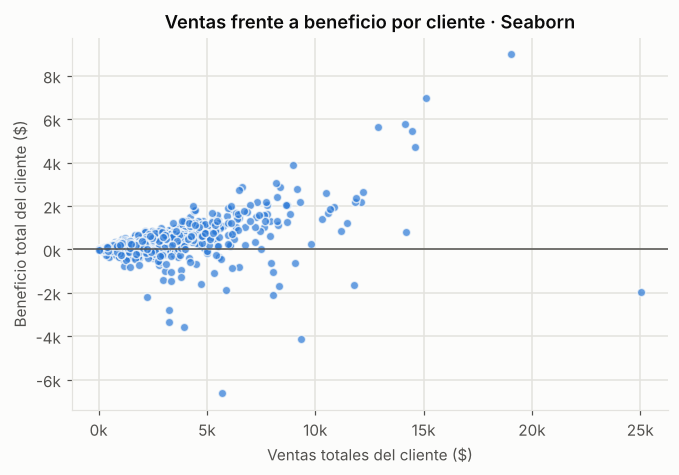

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.4))
sns.scatterplot(data=clientes, x="Sales", y="Profit", s=30, color=PAL[0], alpha=0.7,
                edgecolor=SURFACE, linewidth=1, ax=ax)
ax.axhline(0, color=TEXT2, linewidth=1)
ax.xaxis.set_major_formatter(miles)
ax.yaxis.set_major_formatter(miles)
ax.set(xlabel="Ventas totales del cliente ($)", ylabel="Beneficio total del cliente ($)")
ax.set_title("Ventas frente a beneficio por cliente · Seaborn", loc="center")
plt.show()

**Diferencia:** prácticamente la misma. Seaborn usa nombres de columna en vez de pasarle las columnas. Su ventaja estaría en añadir `hue="Segment"` para colorear por grupos sin bucle.

**Qué se ve:** Hay relación positiva (correlación de 0,51): en general, el cliente que más compra deja más beneficio. Pero hay muchas excepciones: **155 de los 793 clientes dejan pérdidas** (los puntos bajo la línea del 0), y uno de los que más compra (25.000 $) hace perder dinero a la tienda.

## 4. Column Histogram — Distribución

**Pregunta:** ¿cuántos días se tarda en enviar un pedido?

*Del cuaderno de clase:* una variable numérica; cuenta cuántos casos caen en cada intervalo de valores.

- **Cuándo usarlo:** para ver la forma de una distribución: dónde se concentran los datos y si tiene colas.
- **Cómo leerlo:** la altura de cada columna es el número de líneas de pedido enviadas en ese número de días.
- **Evitar:** cambiar el número de intervalos sin revisar. Aquí los días son números enteros, así que ponemos un intervalo por día.

### 4a. Matplotlib

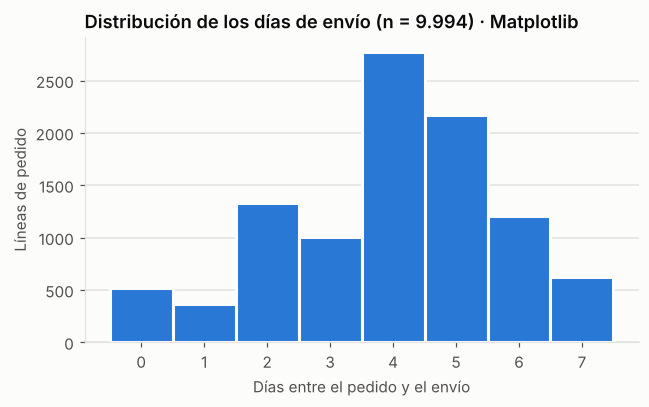

In [15]:
dias = df["Días de envío"]
bordes = np.arange(dias.min() - 0.5, dias.max() + 1.5, 1)   # intervalos centrados en cada día: -0.5–0.5, 0.5–1.5...

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(dias, bins=bordes, color=PAL[0], edgecolor=SURFACE, linewidth=2)   # bins = los bordes de cada columna
ax.set_xticks(range(dias.min(), dias.max() + 1))   # una marca por día
ax.set_xlabel("Días entre el pedido y el envío")
ax.set_ylabel("Líneas de pedido")
ygrid(ax)
ax.set_title(f"Distribución de los días de envío (n = {len(dias):,}) · Matplotlib".replace(",", "."))
plt.show()

### 4b. Seaborn

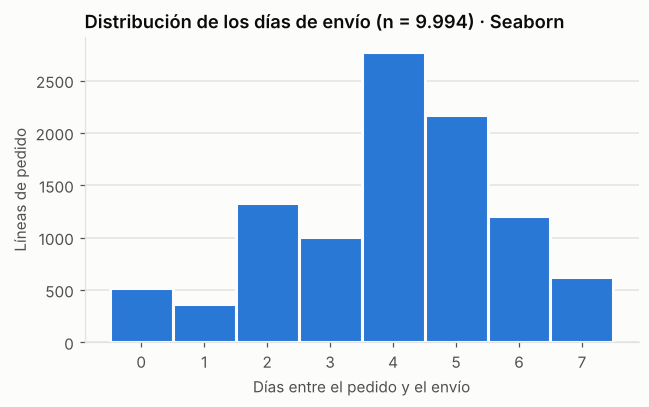

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.histplot(data=df, x="Días de envío",
             discrete=True,          # valores enteros → una columna por día (sustituye al cálculo de "bordes")
             color=PAL[0], edgecolor=SURFACE, linewidth=2,
             alpha=1,                # colores sólidos (histplot pone transparencia por defecto)
             ax=ax)
ax.set_xticks(range(df["Días de envío"].min(), df["Días de envío"].max() + 1))
ax.set(xlabel="Días entre el pedido y el envío", ylabel="Líneas de pedido")
ygrid(ax)
ax.set_title(f"Distribución de los días de envío (n = {len(df):,}) · Seaborn".replace(",", "."))
plt.show()

**Diferencia:** en matplotlib hay que calcular los bordes de los intervalos para centrar cada columna en su día. En seaborn basta con `discrete=True`. Además, con `kde=True` seaborn añadiría la curva suavizada (el *Line Histogram* del cuaderno), que en matplotlib hay que programar a mano.

**Qué se ve:** Lo más habitual es enviar el pedido a los **4 días** (28 % de las líneas) o a los **5 días** (22 %). La mediana es de 4 días. Solo un 5 % sale el mismo día (0 días) y casi nada tarda más de una semana.

## 5. Stacked Column Chart — Composición (pocos periodos)

**Pregunta:** ¿cuánto se vende cada año y cómo se reparte entre las tres categorías?

*Del cuaderno de clase:* pocos periodos; cada columna muestra el total y sus partes en valor absoluto.

- **Cuándo usarlo:** cuando interesan a la vez el total de cada periodo y cómo se reparte.
- **Cómo leerlo:** la altura total es lo vendido ese año; cada segmento es lo que aporta una categoría.
- **Evitar:** comparar segmentos que no están en la base; para eso, mejor barras separadas.

### 5a. Matplotlib

Categoría  Tecnología   Muebles  Material de oficina
Año                                                 
2014         175278.0  157193.0             151776.0
2015         162781.0  170518.0             137233.0
2016         226364.0  198901.0             183940.0
2017         271731.0  215387.0             246097.0


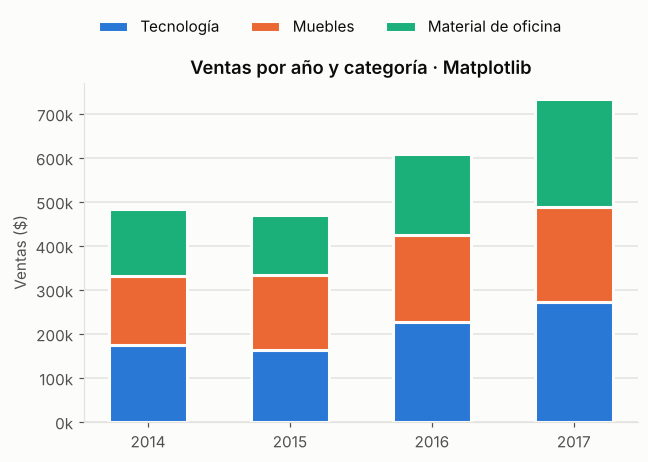

In [17]:
# Datos: tabla año × categoría con la suma de ventas (como la matriz "datos" del cuaderno de clase)
tabla = df.pivot_table(index="Año", columns="Categoría", values="Sales", aggfunc="sum")[ORDEN_CAT]
print(tabla.round(0))

x = np.arange(len(tabla))          # posición de cada columna: 0, 1, 2, 3
bottom = np.zeros(len(tabla))      # dónde empieza cada segmento; al principio, en 0
fig, ax = plt.subplots(figsize=(6.5, 4))
for c, cat in enumerate(ORDEN_CAT):            # un segmento por categoría, apilado encima del anterior
    ax.bar(x, tabla[cat], bottom=bottom, width=0.55, color=COLOR_CAT[cat],
           edgecolor=SURFACE, linewidth=2, label=cat)   # 2 px de separación entre segmentos
    bottom += tabla[cat].values                         # subir la base para la siguiente categoría
ax.set_xticks(x, tabla.index)
ax.yaxis.set_major_formatter(miles)
ax.set_ylabel("Ventas ($)")
ygrid(ax)
ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.1))
ax.set_title("Ventas por año y categoría · Matplotlib", loc="center")
plt.show()

### 5b. Seaborn

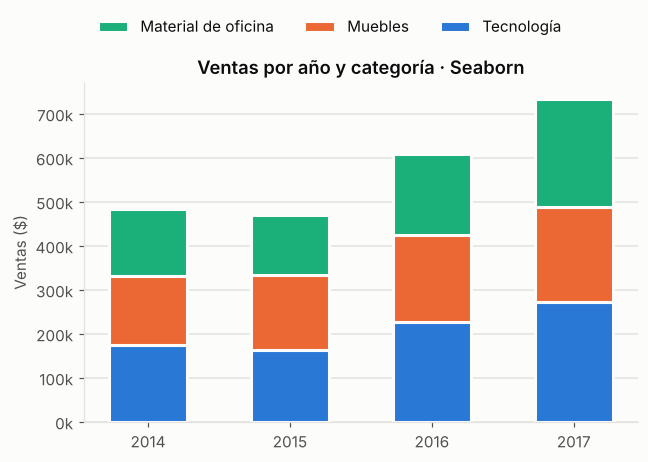

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.histplot(
    data=df.sort_values("Año"),   # ordenado para que los años salgan en orden
    x="Año",                      # una columna por año
    hue="Categoría",              # un segmento por categoría
    hue_order=ORDEN_CAT[::-1],    # seaborn apila el primero ARRIBA; con la lista al revés ([::-1]) Tecnología queda abajo, como en matplotlib
    palette=COLOR_CAT,
    weights="Sales",              # en vez de CONTAR filas, SUMA las ventas
    multiple="stack",             # apila los segmentos (sustituye al bucle con bottom)
    shrink=0.55,                  # ancho de las columnas
    edgecolor=SURFACE, linewidth=2, alpha=1, ax=ax,
)
ax.yaxis.set_major_formatter(miles)
ax.set(xlabel="", ylabel="Ventas ($)")
ygrid(ax)
sns.move_legend(ax, "lower left", bbox_to_anchor=(0, 1.1), ncols=3, title=None)   # leyenda como en la versión matplotlib
ax.set_title("Ventas por año y categoría · Seaborn", loc="center")
plt.show()

**Diferencia:** matplotlib necesita la tabla dinámica (`pivot_table`) y un bucle que vaya subiendo la base (`bottom`). Seaborn lo hace con `weights="Sales"` y `multiple="stack"` sobre los datos originales. Seaborn apila la primera categoría arriba, por eso se le pasa el orden al revés (`[::-1]`) para que quede igual que en matplotlib.

**Qué se ve:** Las ventas totales bajan un poco en el segundo año y después crecen con fuerza hasta los **733.000 $ del último año**, un 51 % más que el primero. **Tecnología** es la categoría que más vende en casi todos los años, y las tres crecen.

## Conclusión

| Gráfico | Matplotlib | Seaborn |
|---|---|---|
| 1. Single Bar | `groupby` + `barh` + `invert_yaxis` | `barplot(estimator="sum")` sobre los datos sin agrupar |
| 2. Line | `plot` | `lineplot` (con `hue` haría varias líneas sin bucle) |
| 3. Scatter | `scatter` | `scatterplot` (con `hue` colorearía grupos) |
| 4. Column Histogram | calcular `bins` a mano | `histplot(discrete=True)` |
| 5. Stacked Column | `pivot_table` + bucle con `bottom` | `histplot(weights=, multiple="stack")` |

- **Matplotlib** da control total, pero hay que preparar los datos y hacer bucles.
- **Seaborn** trabaja directamente con el DataFrame y resuelve con un parámetro lo que en matplotlib son varias líneas. Como dibuja sobre matplotlib, los retoques (títulos, ejes, formato) se hacen igual.

**Lo que dicen los datos:** teléfonos y sillas lideran las ventas; las ventas crecen y tienen un pico claro a final de año; vender más a un cliente no garantiza ganar dinero con él (1 de cada 5 clientes deja pérdidas); los pedidos se envían normalmente en 4-5 días; y Tecnología es la categoría que más aporta.